In [2]:
import numpy as np
from pathlib import Path

data_dir = Path("../data.nosync/60s")

In [27]:
datas = np.concatenate([np.load(f)['values'] for f in data_dir.glob("**/*.npz")], axis=0)
users = np.concatenate([[f'{val}-{str(f).split("/")[-2]}' for val in np.load(f)['groups']] for f in data_dir.glob("**/*.npz")], axis=0)
# datasets = np.concatenate([f.split("/")[-1] for f in data_dir.glob("**/*.npz")], axis=0)

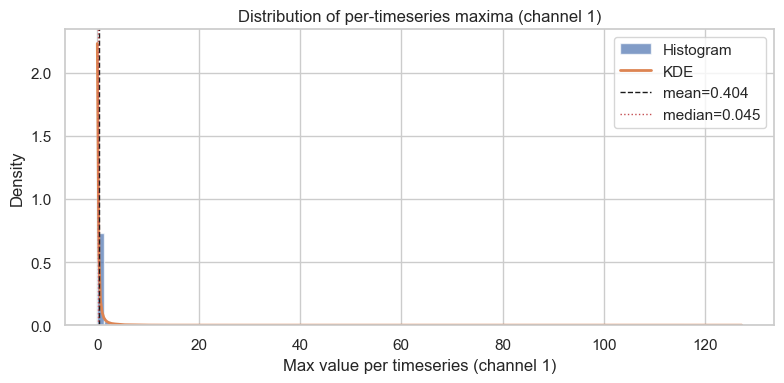

In [7]:
from scipy.stats import gaussian_kde

import matplotlib.pyplot as plt

# compute per-timeseries maximum on channel 1 (index 1)
max_ch1 = datas[:, :, 1].max(axis=1)

plt.figure(figsize=(8, 4))
plt.hist(max_ch1, bins=100, density=True, alpha=0.7, color='C0', label='Histogram')

# overlay KDE if scipy is available
try:
    import numpy as _np  # small local import to build xs
    kde = gaussian_kde(max_ch1)
    xs = _np.linspace(max_ch1.min(), max_ch1.max(), 400)
    plt.plot(xs, kde(xs), color='C1', lw=2, label='KDE')
except Exception:
    pass

mean_val = max_ch1.mean()
median_val = np.median(max_ch1)
plt.axvline(mean_val, color='k', linestyle='--', lw=1, label=f'mean={mean_val:.3f}')
plt.axvline(median_val, color='r', linestyle=':', lw=1, label=f'median={median_val:.3f}')

plt.xlabel('Max value per timeseries (channel 1)')
plt.ylabel('Density')
plt.title('Distribution of per-timeseries maxima (channel 1)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

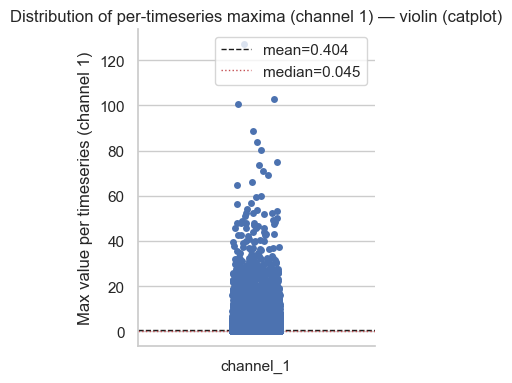

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# prepare dataframe for seaborn catplot
df = pd.DataFrame({'value': max_ch1, 'category': 'channel_1'})

sns.set(style='whitegrid')
g = sns.catplot(x='category', y='value', data=df,

                height=4, aspect=0.8, color='C0')
ax = g.ax

# add mean and median horizontal lines
ax.axhline(mean_val, color='k', linestyle='--', lw=1, label=f'mean={mean_val:.3f}')
ax.axhline(median_val, color='r', linestyle=':', lw=1, label=f'median={median_val:.3f}')

ax.set_xlabel('')
ax.set_ylabel('Max value per timeseries (channel 1)')
ax.set_title('Distribution of per-timeseries maxima (channel 1) — violin (catplot)')
ax.legend()
plt.tight_layout()
plt.show()


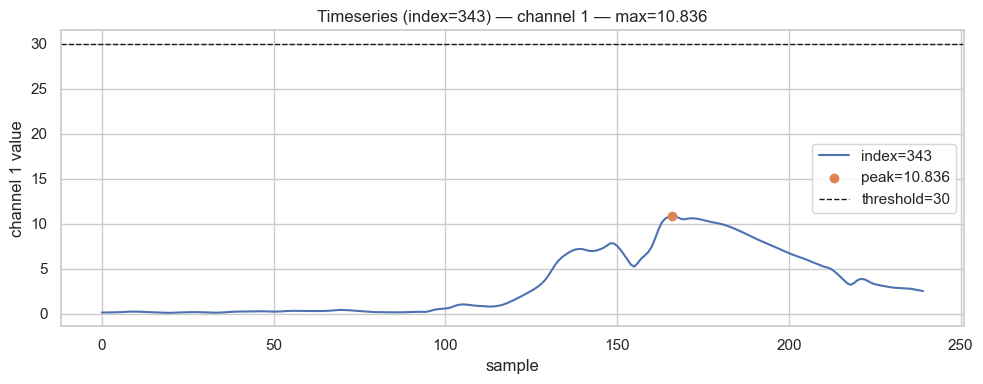

In [30]:
# find a timeseries with max > 30 and plot its channel 1
candidates = np.where(max_ch1 > 10)[0]
if candidates.size == 0:
    print("No timeseries with max > 30 found.")
else:
    idx = candidates[10]
    ts = datas[idx, :, 1]
    t = np.arange(ts.shape[0])

    plt.figure(figsize=(10, 4))
    plt.plot(t, ts, lw=1.5, label=f'index={idx}')
    peak_i = int(ts.argmax())
    plt.scatter([peak_i], [ts[peak_i]], color='C1', zorder=5, label=f'peak={ts[peak_i]:.3f}')
    plt.axhline(30, color='k', linestyle='--', lw=1, label='threshold=30')

    plt.title(f"Timeseries (index={idx}) — channel 1 — max={ts.max():.3f}")
    plt.xlabel('sample')
    plt.ylabel('channel 1 value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()